In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [16]:
# 1. Read the image
img = cv2.imread("/content/cat.jpg", cv2.IMREAD_GRAYSCALE)

# Check whether the image was loaded
if img is None:
    raise FileNotFoundError(
        "Image not found. Upload image.jpg to /content/ first."
    )

In [17]:

# 2. Apply Fourier Transform
F = np.fft.fftshift(np.fft.fft2(img))

In [18]:
# 3. Create frequency distance matrix
M, N = img.shape
u, v = np.meshgrid(
    np.arange(N) - N // 2,
    np.arange(M) - M // 2
)
D = np.sqrt(u**2 + v**2)


In [19]:
# 4. Create Low-Pass and High-Pass Filters
cutoff = 30
LPF = (D < cutoff).astype(float)
HPF = (D >= cutoff).astype(float)

In [20]:
# 5. Apply Low-Pass Filter (Smoothing)
smooth = np.abs(
    np.fft.ifft2(np.fft.ifftshift(F * LPF))
)

In [21]:
# 6. Apply High-Pass Filter (Edge Details)
high_pass = np.abs(
    np.fft.ifft2(np.fft.ifftshift(F * HPF))
)


In [22]:
# 7. Sharpen the original image
sharp = np.clip(
    img.astype(float) + high_pass,
    0, 255
).astype(np.uint8)

# Convert smoothing result to uint8
smooth = np.clip(smooth, 0, 255).astype(np.uint8)

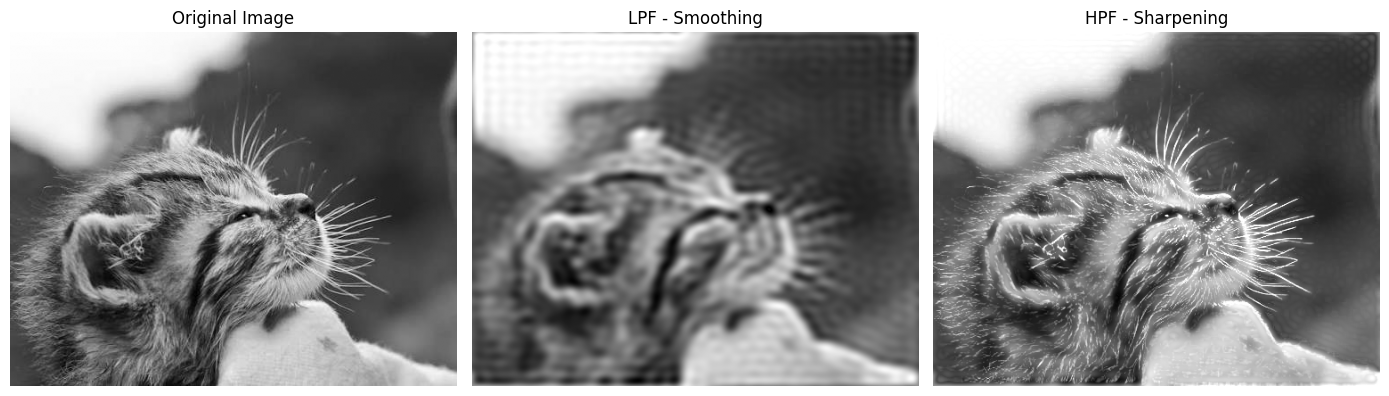

In [24]:
# 8. Display all images
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap='gray')
plt.title('LPF - Smoothing')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap='gray')
plt.title('HPF - Sharpening')
plt.axis('off')

plt.tight_layout()
plt.show()

